In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
PROJECT_DIR = "/content/drive/MyDrive/hausa_news_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

Mounted at /content/drive


In [ ]:
!pip install -q datasets pandas matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# ====== CHANGE THIS ======
LANG_CODE = "hau"   # e.g. hau, yor, ibo, amh, swa, run, sna, som, xho, lug, lin, orm, tir
# =========================

SEED = 42

try:
    ds = load_dataset("masakhane/masakhanews", LANG_CODE)
except Exception as e:
    print("Primary load failed:", e)
    # Fallback for newer `datasets` versions that dropped loading scripts
    ds = load_dataset("masakhane/masakhanews", LANG_CODE, trust_remote_code=True)

print(ds)

train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()

print(train_df.columns.tolist())
train_df.head()

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/5.58M [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/770k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2219 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/317 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/637 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 2219
    })
    validation: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 317
    })
    test: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 637
    })
})
['category', 'headline', 'text', 'url']


,category,headline,text,url
0,religion,Yadda Shugaban Kungiyar Kirista ya gina masall...,A wani abu da ba a saba gani ba a ƙasa irin Na...,https://www.bbc.com/hausa/labarai-56727491
1,entertainment,Burina na zama hamshakiyar 'yar kasuwa – Rayya...,Tauraruwar fina-finan Hausa Surayya Aminu wacc...,https://www.bbc.com/hausa/labarai-52923642
2,business,Ƙoƙarin da muke yi na haƙo man fetur a Gombe d...,Shirin Gane Mini Hanya na wannan makon ya tatt...,https://www.bbc.com/hausa/articles/cqe990jj1qyo
3,health,Yadda kyanda ke barazana a duniya,"Sama da mutum 140,000 suka mutu sakamakon cuta...",https://www.bbc.com/hausa/labarai-50681571
4,politics,Babangida Aliyu: 'Yan Najeriya na kewar shekar...,Tsohon gwamnan Jihar Neja da ke arewacin Najer...,https://www.bbc.com/hausa/wasanni-61669666


In [ ]:
# Combine headline + body (the dataset provides these separately)
def build_text(df):
    df = df.copy()
    df["text_full"] = (df["headline"].fillna("") + ". " + df["text"].fillna("")).str.strip()
    return df

train_df, val_df, test_df = map(build_text, [train_df, val_df, test_df])

# Labels may be ints (ClassLabel) or strings; normalize to names
label_feature = ds["train"].features["category"]
if hasattr(label_feature, "names"):
    id2label = {i: n for i, n in enumerate(label_feature.names)}
    for df in (train_df, val_df, test_df):
        df["label_name"] = df["category"].map(id2label)
else:
    for df in (train_df, val_df, test_df):
        df["label_name"] = df["category"]

labels = sorted(train_df["label_name"].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}
for df in (train_df, val_df, test_df):
    df["label_id"] = df["label_name"].map(label2id)

print("Classes:", labels)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Classes: ['business', 'entertainment', 'health', 'politics', 'religion', 'sports', 'technology']
Train: 2219 | Val: 317 | Test: 637


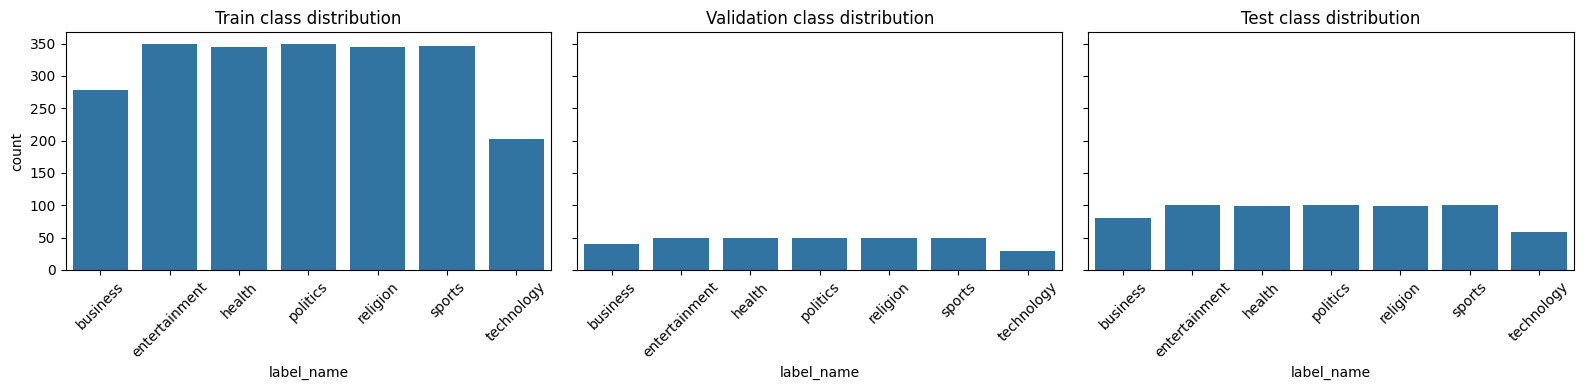

label_name
entertainment    15.8
politics         15.8
sports           15.6
health           15.5
religion         15.5
business         12.6
technology        9.1
Name: proportion, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, df) in zip(axes, [("Train", train_df), ("Validation", val_df), ("Test", test_df)]):
    order = labels
    sns.countplot(data=df, x="label_name", order=order, ax=ax)
    ax.set_title(f"{name} class distribution")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

print((train_df["label_name"].value_counts(normalize=True) * 100).round(1))

count    2219.0
mean      448.3
std       393.3
min         4.0
25%       175.5
50%       344.0
75%       604.0
max      2950.0
Name: n_words, dtype: float64


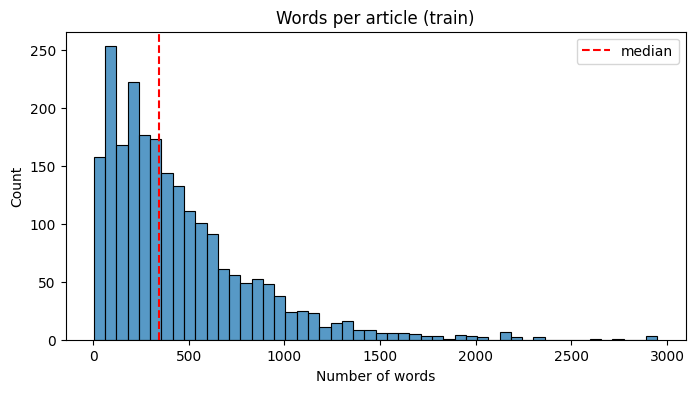

In [ ]:
for df in (train_df, val_df, test_df):
    df["n_words"] = df["text_full"].str.split().str.len()
    df["n_chars"] = df["text_full"].str.len()

print(train_df["n_words"].describe().round(1))

plt.figure(figsize=(8, 4))
sns.histplot(train_df["n_words"], bins=50)
plt.axvline(train_df["n_words"].median(), color="red", linestyle="--", label="median")
plt.title("Words per article (train)")
plt.xlabel("Number of words")
plt.legend()
plt.savefig("length_distribution.png", dpi=150)
plt.show()

In [ ]:
# Empty / very short texts
print("Empty texts:", (train_df["text_full"].str.len() < 5).sum())
print("Very short (<10 words):", (train_df["n_words"] < 10).sum())

# Duplicates within train
print("Duplicate texts in train:", train_df["text_full"].duplicated().sum())

# Leakage between splits (important for honest evaluation)
train_set = set(train_df["text_full"])
print("Train/Test overlap:", test_df["text_full"].isin(train_set).sum())
print("Train/Val overlap:", val_df["text_full"].isin(train_set).sum())

# Vocabulary size and most frequent tokens
from collections import Counter
tokens = Counter(w.lower() for t in train_df["text_full"] for w in t.split())
print("Vocabulary size:", len(tokens))
print("Top 20 tokens:", tokens.most_common(20))

# Sample articles per class
for lab in labels:
    print(f"\n=== {lab} ===")
    print(train_df[train_df["label_name"] == lab]["text_full"].iloc[0][:300])

Empty texts: 0
Very short (<10 words): 8
Duplicate texts in train: 0
Train/Test overlap: 0
Train/Val overlap: 0
Vocabulary size: 52228
Top 20 tokens: [('da', 76088), ('a', 40107), ('ya', 25841), ('ta', 23343), ('na', 18419), ('yi', 11211), ('kuma', 10437), ('ba', 10337), ('ne', 9197), ('ke', 7995), ('su', 7966), ('ce', 7733), ('za', 6393), ('kan', 6142), ('daga', 5988), ('suka', 5788), ('cewa', 5612), ('mai', 5569), ('shi', 5148), ('cikin', 5138)]

=== business ===
Ƙoƙarin da muke yi na haƙo man fetur a Gombe da Bauchi - Gwamna Inuwa Yahaya. Shirin Gane Mini Hanya na wannan makon ya tattauna da Gwamnan Gombe Muhammadu Inuwa Yahaya game da shirinsu na haƙo man fetur a jihohin Bauchi da Gombe.

=== entertainment ===
Burina na zama hamshakiyar 'yar kasuwa – Rayya Kwana Casa'in. Tauraruwar fina-finan Hausa Surayya Aminu wacce aka fi sani da Rayya a cikin shirin talabijin na Kwana Casa'in na tashar Arewa24 ta ce tana da burin zama hamshakiyar 'yar kasuwa. Fitacciyar 'yar wasan Hausan ta bay

In [ ]:
import re

def clean_text(t):
    t = re.sub(r"http\S+|www\.\S+", " ", t)      # URLs
    t = re.sub(r"\s+", " ", t).strip()            # whitespace
    return t

for df in (train_df, val_df, test_df):
    df["text_clean"] = df["text_full"].apply(clean_text)

# Drop empty rows and exact duplicates in train
train_df = train_df[train_df["text_clean"].str.len() > 0].drop_duplicates("text_clean").reset_index(drop=True)
val_df   = val_df[val_df["text_clean"].str.len() > 0].reset_index(drop=True)
test_df  = test_df[test_df["text_clean"].str.len() > 0].reset_index(drop=True)

keep = ["text_clean", "label_name", "label_id"]
train_df[keep].to_csv("train.csv", index=False)
val_df[keep].to_csv("val.csv", index=False)
test_df[keep].to_csv("test.csv", index=False)

import json
json.dump({"label2id": label2id, "id2label": id2label}, open("labels.json", "w"))
print("Saved train.csv, val.csv, test.csv, labels.json")
print(f"Final sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Saved train.csv, val.csv, test.csv, labels.json
Final sizes -> Train: 2219 | Val: 317 | Test: 637
